# NGC 253 catalogue spectra from streamed ESO cubelets

This notebook extracts full MUSE spectra for a fixed sample of **10 recovered catalogue PNe, 10 missed catalogue PNe, and 10 unmatched network candidates**—without downloading the 364-GB mosaic cube and without rerunning `Striding_4channel_diagnostics-v5.ipynb`. It uses ESO's SODA service to stream small spatial cubelets, saves one compressed `.npz` checkpoint per object, and deletes each temporary FITS cubelet immediately.

Decisions implemented here:

- deterministic 10-object samples from each saved population in `diagnostic_source_measurements_v4.2.csv`;
- catalogue coordinates by default for recovered/missed catalogue PNe; unmatched candidates always use their network peaks; an option can use matched network peaks for recovered objects too;
- 3-pixel aperture and 6–9-pixel local annulus;
- both aperture-only and aperture-minus-background spectra;
- propagated 1-sigma uncertainties from `STAT`; non-zero `DQ` pixels are rejected;
- rest-frame wavelengths using only `OIII5006_VEL` from the MAPS file plus `VSYS=235.36 km/s`—no line refitting;
- absolute flux density by default, with optional [O III] 5007 peak normalisation;
- missing/AO-gap channels remain missing and are shaded, never interpolated;
- resumable `.npz` checkpoints and a lightweight CSV index; no combined FITS file.

ESO cube: `ADP.2025-07-06T07:52:11.871` (`NGC0253.fits`, `SCIENCE.CUBE.IFS`). The full 4600–9400 Å range is requested in two spectral chunks because ESO notes that very large SODA requests can time out.

In [1]:
from __future__ import annotations

import json
import math
import os
import re
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from astropy.io import fits
from astropy.stats import sigma_clip
from astropy.wcs import WCS
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170})

## Configuration

Set `COORDINATE_MODE` to `"catalogue"` for the unbiased default. `"matched_detection"` uses the matched network peak for recovered objects and catalogue coordinates for missed objects. The two modes write to separate checkpoint directories.

In [2]:
DIAGNOSTICS_CSV = Path('/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/diagnostic_source_measurements_v4.2.csv')
CATALOG_CSV = Path('/Users/golta/Neb_det/data/PN_CAT.csv')
MAPS_FITS = Path('/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits')
OUTPUT_ROOT = Path.cwd() / 'NGC253_cube_catalogue_spectra'

ESO_DP_ID = 'ADP.2025-07-06T07:52:11.871'
ESO_PUBLISHER_ID = f'ivo://eso.org/ID?{ESO_DP_ID}'
SODA_URL = 'https://dataportal.eso.org/dataPortal/soda/sync'
# Full released cube range, split to make archive timeouts less likely.
SPECTRAL_CHUNKS_M = [(4.6e-7, 7.0e-7), (7.0e-7, 9.4e-7)]

COORDINATE_MODE = 'catalogue'  # or 'matched_detection'
SAMPLE_PER_POPULATION = 20
SAMPLE_SEED = 20261014  # fixed so reruns select the same 30 objects
APERTURE_RADIUS_PIX = 3.0
BACKGROUND_INNER_PIX = 6.0
BACKGROUND_OUTER_PIX = 9.0
CUTOUT_RADIUS_ARCSEC = 2.2  # comfortably contains the 9-pixel annulus at 0.2 arcsec/pixel
VSYS_KMS = 235.36
C_KMS = 299792.458
MEDIAN_STD_FACTOR = 1.2533141373155
REFERENCE_LINES = {
    r'H$\beta$': (4861.33, '#7b2cbf'),
    r'[O III] $\lambda5007$': (5006.84, '#2a9d8f'),
    r'H$\alpha$': (6562.80, '#e76f51'),
    r'[N II] $\lambda6583$': (6583.45, '#bc4749'),
}

MAX_DOWNLOAD_ATTEMPTS = 5
REQUEST_TIMEOUT = (30, 480)
PAUSE_BETWEEN_OBJECTS_S = 0.5
PAGE_SIZE = 10

RUN_LABEL = f'sample{SAMPLE_PER_POPULATION}_{COORDINATE_MODE}_seed{SAMPLE_SEED}'
CHECKPOINT_DIR = OUTPUT_ROOT / f'checkpoints_{RUN_LABEL}'
TEMP_DIR = OUTPUT_ROOT / 'temporary_cubelets'
PLOT_DIR = OUTPUT_ROOT / f'pages_{RUN_LABEL}'
INDEX_CSV = OUTPUT_ROOT / f'spectra_index_{RUN_LABEL}.csv'
for directory in [OUTPUT_ROOT, CHECKPOINT_DIR, TEMP_DIR, PLOT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print('Coordinate mode:', COORDINATE_MODE)
print('Checkpoints:', CHECKPOINT_DIR)

Coordinate mode: catalogue
Checkpoints: /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/checkpoints_sample20_catalogue_seed20261014


## Load the saved populations, coordinates, and velocity map

This cell reads existing products only. It does not load the neural network or rerun inference. `OIII5006_VEL` is a velocity relative to the systemic velocity. The value at the selected coordinate is reported unchanged; `VSYS` is added only for the wavelength correction.

In [3]:
RECOVERED = 'Recovered catalogue PN'
MISSED = 'Missed catalogue PN'
UNMATCHED = 'Unmatched candidate'
POPULATIONS = [RECOVERED, MISSED, UNMATCHED]

def validate_local_inputs():
    for path in [DIAGNOSTICS_CSV, CATALOG_CSV, MAPS_FITS]:
        if not path.is_file():
            raise FileNotFoundError(path)

def safe_object_name(object_id):
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', str(object_id))

def prepare_targets(coordinate_mode='catalogue', n_per_population=SAMPLE_PER_POPULATION, seed=SAMPLE_SEED):
    if coordinate_mode not in {'catalogue', 'matched_detection'}:
        raise ValueError('coordinate_mode must be catalogue or matched_detection')
    validate_local_inputs()
    diagnostics = pd.read_csv(DIAGNOSTICS_CSV)
    diagnostics = diagnostics[diagnostics['population'].isin(POPULATIONS)].copy()
    sampled_groups = []
    for population_number, population in enumerate(POPULATIONS):
        group = diagnostics[diagnostics['population'].eq(population)]
        if len(group) < n_per_population:
            raise ValueError(f'{population} has only {len(group)} rows; requested {n_per_population}')
        sampled_groups.append(group.sample(n=n_per_population, random_state=seed + population_number))
    targets = pd.concat(sampled_groups, ignore_index=True)

    catalogue = pd.read_csv(CATALOG_CSV)[['ID', 'RAdeg', 'DEdeg']].set_index('ID')
    targets['RAdeg'] = targets['catalog_id'].map(catalogue['RAdeg'])
    targets['DEdeg'] = targets['catalog_id'].map(catalogue['DEdeg'])

    with fits.open(MAPS_FITS, memmap=True, lazy_load_hdus=True) as hdul:
        map_wcs = WCS(hdul['OIII5006_FLUX'].header).celestial
        velocity_map = hdul['OIII5006_VEL'].data
        map_vsys = float(hdul[0].header.get('VSYS', VSYS_KMS))

        recovered = targets['population'].eq(RECOVERED)
        missed = targets['population'].eq(MISSED)
        unmatched = targets['population'].eq(UNMATCHED)
        use_catalogue = missed | (recovered & (coordinate_mode == 'catalogue'))
        targets['extract_x'] = np.where(use_catalogue, targets['catalog_x'], targets['center_x'])
        targets['extract_y'] = np.where(use_catalogue, targets['catalog_y'], targets['center_y'])
        network_ra, network_dec = map_wcs.pixel_to_world_values(
            targets['extract_x'].to_numpy(), targets['extract_y'].to_numpy()
        )
        targets['extract_ra'] = np.where(use_catalogue, targets['RAdeg'], network_ra)
        targets['extract_dec'] = np.where(use_catalogue, targets['DEdeg'], network_dec)
        targets['coordinate_source'] = np.select(
            [unmatched, use_catalogue, recovered],
            ['unmatched network peak', 'catalogue', 'matched network detection'],
            default='network peak',
        )

        velocities = []
        for x, y in zip(targets['extract_x'], targets['extract_y']):
            xi, yi = int(round(x)), int(round(y))
            if 0 <= yi < velocity_map.shape[0] and 0 <= xi < velocity_map.shape[1]:
                velocities.append(float(velocity_map[yi, xi]))
            else:
                velocities.append(np.nan)

    targets['oiii5006_vel_kms'] = velocities  # reported MAPS value, relative to VSYS
    targets['vsys_kms'] = map_vsys
    targets['rest_correction_velocity_kms'] = map_vsys + targets['oiii5006_vel_kms']
    targets['checkpoint'] = [str(CHECKPOINT_DIR / f'{safe_object_name(x)}.npz') for x in targets['object_id']]
    targets['sample_seed'] = seed
    order = {RECOVERED: 0, MISSED: 1, UNMATCHED: 2}
    targets['_order'] = targets['population'].map(order)
    return targets.sort_values(['_order', 'network_score'], ascending=[True, False]).drop(columns='_order').reset_index(drop=True)

targets = prepare_targets(COORDINATE_MODE)
display(targets.groupby('population').size().rename('N').to_frame())
display(targets[['object_id', 'population', 'extract_ra', 'extract_dec', 'coordinate_source', 'oiii5006_vel_kms']].head())

,N
population,
Missed catalogue PN,20
Recovered catalogue PN,20
Unmatched candidate,20


,object_id,population,extract_ra,extract_dec,coordinate_source,oiii5006_vel_kms
0,PN_338,Recovered catalogue PN,11.936045,-25.288753,catalogue,-142.576233
1,PN_529,Recovered catalogue PN,11.842295,-25.323120,catalogue,171.070038
2,PN_115,Recovered catalogue PN,11.794669,-25.370329,catalogue,220.599091
3,PN_365,Recovered catalogue PN,11.902256,-25.310424,catalogue,102.008232
4,PN_336,Recovered catalogue PN,11.944388,-25.297980,catalogue,-38.267796


## ESO session and cubelet download

HTTP 429/5xx errors and timeouts are retried with exponential backoff. Every download goes to a temporary FITS file and is deleted in a `finally` block after extraction.

In [4]:
def make_http_session():
    retry = Retry(
        total=MAX_DOWNLOAD_ATTEMPTS,
        connect=MAX_DOWNLOAD_ATTEMPTS,
        read=MAX_DOWNLOAD_ATTEMPTS,
        status=MAX_DOWNLOAD_ATTEMPTS,
        backoff_factor=2.0,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(['GET']),
        raise_on_status=False,
    )
    session = requests.Session()
    session.mount('https://', HTTPAdapter(max_retries=retry))
    session.headers.update({'User-Agent': 'NGC253-PN-cubelet-notebook/1.0'})
    return session

HTTP = make_http_session()

def download_cubelet(ra_deg, dec_deg, band_m, session=HTTP):
    handle = tempfile.NamedTemporaryFile(prefix='ngc253_cubelet_', suffix='.fits', dir=TEMP_DIR, delete=False)
    temp_path = Path(handle.name)
    handle.close()
    params = {
        'ID': ESO_PUBLISHER_ID,
        'CIRCLE': f'{ra_deg:.10f} {dec_deg:.10f} {CUTOUT_RADIUS_ARCSEC / 3600.0:.12f}',
        'BAND': f'{band_m[0]:.12g} {band_m[1]:.12g}',
    }
    try:
        with session.get(SODA_URL, params=params, stream=True, timeout=REQUEST_TIMEOUT) as response:
            response.raise_for_status()
            with temp_path.open('wb') as stream:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        stream.write(chunk)
        if temp_path.stat().st_size < 2880:
            raise RuntimeError('SODA response is too small to be a FITS file')
        with temp_path.open('rb') as stream:
            if stream.read(6) != b'SIMPLE':
                raise RuntimeError('SODA response is not a FITS file')
        return temp_path
    except Exception:
        temp_path.unlink(missing_ok=True)
        raise

## Aperture and annulus extraction

`DATA` is summed inside the circular aperture. The annular spectrum is a sigma-clipped median at each wavelength. The background-subtracted spectrum is `aperture_sum - N_aperture × annulus_median`. `STAT` is treated as variance. The uncertainty of the median uses the same Gaussian approximation as the diagnostic notebook.

In [5]:
def wavelength_axis_angstrom(header, n_wave):
    # ESO cubelets have a linear AWAV axis in Angstrom. This explicit form avoids
    # coupling the spectral axis to the celestial WCS.
    crpix = float(header.get('CRPIX3', 1.0))
    crval = float(header['CRVAL3'])
    step = float(header.get('CD3_3', header.get('CDELT3')))
    pixels_fits = np.arange(n_wave, dtype=float) + 1.0
    wavelength = crval + (pixels_fits - crpix) * step
    unit = str(header.get('CUNIT3', 'Angstrom')).strip().lower()
    if unit in {'m', 'meter', 'metre'}:
        wavelength *= 1e10
    elif unit in {'nm', 'nanometer', 'nanometre'}:
        wavelength *= 10.0
    return wavelength

def extract_cubelet_spectra(cubelet_path, ra_deg, dec_deg):
    with fits.open(cubelet_path, memmap=True) as hdul:
        data = np.asarray(hdul['DATA'].data, dtype=np.float64)
        variance = np.asarray(hdul['STAT'].data, dtype=np.float64)
        dq = np.asarray(hdul['DQ'].data) if 'DQ' in hdul else np.zeros_like(data, dtype=np.uint8)
        header = hdul['DATA'].header
        wavelength = wavelength_axis_angstrom(header, data.shape[0])
        x, y = WCS(header).celestial.world_to_pixel_values(ra_deg, dec_deg)

        yy, xx = np.mgrid[:data.shape[1], :data.shape[2]]
        radius = np.hypot(xx - x, yy - y)
        aperture_geometry = radius <= APERTURE_RADIUS_PIX
        background_geometry = (radius >= BACKGROUND_INNER_PIX) & (radius < BACKGROUND_OUTER_PIX)
        valid = np.isfinite(data) & np.isfinite(variance) & (variance >= 0) & (dq == 0)

        ap_values = np.where(valid[:, aperture_geometry], data[:, aperture_geometry], np.nan)
        ap_variances = np.where(valid[:, aperture_geometry], variance[:, aperture_geometry], np.nan)
        ap_n = np.sum(np.isfinite(ap_values), axis=1)
        aperture_flux = np.nansum(ap_values, axis=1)
        aperture_variance = np.nansum(ap_variances, axis=1)
        aperture_flux[ap_n < 3] = np.nan
        aperture_variance[ap_n < 3] = np.nan

        bg_values = np.ma.array(
            data[:, background_geometry],
            mask=~valid[:, background_geometry],
        )
        bg_variances = np.ma.array(
            variance[:, background_geometry],
            mask=~valid[:, background_geometry],
        )
        clipped = sigma_clip(bg_values, sigma=3.0, maxiters=5, axis=1, cenfunc='median', stdfunc='mad_std')
        combined_mask = np.ma.getmaskarray(clipped)
        bg_n = np.sum(~combined_mask, axis=1)
        background = np.asarray(np.ma.median(clipped, axis=1).filled(np.nan), dtype=float)
        kept_bg_var = np.ma.array(bg_variances.data, mask=combined_mask | np.ma.getmaskarray(bg_variances))
        bg_var_sum = np.asarray(np.ma.sum(kept_bg_var, axis=1).filled(np.nan), dtype=float)
        background_error = MEDIAN_STD_FACTOR * np.sqrt(bg_var_sum) / np.maximum(bg_n, 1)
        background[bg_n < 10] = np.nan
        background_error[bg_n < 10] = np.nan

        background_subtracted = aperture_flux - ap_n * background
        background_subtracted_variance = aperture_variance + (ap_n * background_error) ** 2

        return {
            'wavelength_observed_A': wavelength,
            'aperture_flux': aperture_flux,
            'aperture_flux_err': np.sqrt(aperture_variance),
            'background_per_pixel': background,
            'background_per_pixel_err': background_error,
            'background_subtracted_flux': background_subtracted,
            'background_subtracted_flux_err': np.sqrt(background_subtracted_variance),
            'aperture_npix': ap_n.astype(np.int16),
            'background_npix': bg_n.astype(np.int16),
            'cubelet_x': float(x),
            'cubelet_y': float(y),
            'flux_unit': str(header.get('BUNIT', 'native FITS units')),
        }

def relativistic_rest_wavelength(wavelength_observed_A, radial_velocity_kms):
    beta = radial_velocity_kms / C_KMS
    if not np.isfinite(beta) or abs(beta) >= 1:
        return np.full_like(wavelength_observed_A, np.nan, dtype=float)
    return wavelength_observed_A * np.sqrt((1.0 - beta) / (1.0 + beta))

def concatenate_chunks(chunks):
    keys = [
        'wavelength_observed_A', 'aperture_flux', 'aperture_flux_err',
        'background_per_pixel', 'background_per_pixel_err',
        'background_subtracted_flux', 'background_subtracted_flux_err',
        'aperture_npix', 'background_npix',
    ]
    merged = {key: np.concatenate([chunk[key] for chunk in chunks]) for key in keys}
    order = np.argsort(merged['wavelength_observed_A'])
    for key in keys:
        merged[key] = merged[key][order]
    rounded = np.round(merged['wavelength_observed_A'], 6)
    _, unique_indices = np.unique(rounded, return_index=True)
    unique_indices.sort()
    for key in keys:
        merged[key] = merged[key][unique_indices]
    merged['flux_unit'] = chunks[0]['flux_unit']
    return merged

## Resumable extraction to one `.npz` per object

Use `limit=1` first. Existing valid checkpoints are skipped. A failed object is recorded in the CSV and does not erase completed work. The selected 30 objects should transfer roughly 0.5 GB in total, while no 364-GB cube is stored.

In [7]:
def checkpoint_is_valid(path):
    path = Path(path)
    if not path.is_file():
        return False
    try:
        with np.load(path, allow_pickle=False) as saved:
            required = {'wavelength_rest_A', 'aperture_flux', 'background_subtracted_flux', 'object_id'}
            return required.issubset(saved.files) and len(saved['wavelength_rest_A']) > 1000
    except Exception:
        return False

def save_checkpoint_atomic(path, arrays):
    path = Path(path)
    handle = tempfile.NamedTemporaryFile(prefix=path.stem + '_', suffix='.npz', dir=path.parent, delete=False)
    temp_path = Path(handle.name)
    handle.close()
    try:
        np.savez_compressed(temp_path, **arrays)
        with np.load(temp_path, allow_pickle=False) as test:
            if len(test['wavelength_rest_A']) < 1000:
                raise RuntimeError('Checkpoint validation failed')
        os.replace(temp_path, path)
    finally:
        temp_path.unlink(missing_ok=True)

def extract_one_object(target, session=HTTP, overwrite=False):
    checkpoint = Path(target.checkpoint)
    if checkpoint_is_valid(checkpoint) and not overwrite:
        return {'status': 'cached', 'checkpoint_bytes': checkpoint.stat().st_size}

    chunks = []
    transferred = 0
    started = time.time()
    for band in SPECTRAL_CHUNKS_M:
        cubelet_path = None
        try:
            cubelet_path = download_cubelet(target.extract_ra, target.extract_dec, band, session=session)
            transferred += cubelet_path.stat().st_size
            chunks.append(extract_cubelet_spectra(cubelet_path, target.extract_ra, target.extract_dec))
        finally:
            if cubelet_path is not None:
                cubelet_path.unlink(missing_ok=True)

    merged = concatenate_chunks(chunks)
    relative_velocity = float(target.oiii5006_vel_kms)
    correction_velocity = float(target.rest_correction_velocity_kms)
    rest_wave = relativistic_rest_wavelength(merged['wavelength_observed_A'], correction_velocity)
    arrays = {
        **{key: value for key, value in merged.items() if key != 'flux_unit'},
        'wavelength_rest_A': rest_wave,
        'object_id': np.array(str(target.object_id)),
        'catalog_id': np.array(float(target.catalog_id)),
        'population': np.array(str(target.population)),
        'network_score': np.array(float(target.network_score)),
        'coordinate_mode': np.array(COORDINATE_MODE),
        'sample_seed': np.array(SAMPLE_SEED),
        'coordinate_source': np.array(str(target.coordinate_source)),
        'ra_deg': np.array(float(target.extract_ra)),
        'dec_deg': np.array(float(target.extract_dec)),
        'oiii5006_vel_kms': np.array(relative_velocity),
        'vsys_kms': np.array(float(target.vsys_kms)),
        'rest_correction_velocity_kms': np.array(correction_velocity),
        'flux_unit': np.array(merged['flux_unit']),
        'eso_dp_id': np.array(ESO_DP_ID),
        'aperture_radius_pix': np.array(APERTURE_RADIUS_PIX),
        'background_inner_pix': np.array(BACKGROUND_INNER_PIX),
        'background_outer_pix': np.array(BACKGROUND_OUTER_PIX),
    }
    save_checkpoint_atomic(checkpoint, arrays)
    return {
        'status': 'complete',
        'transferred_bytes': transferred,
        'checkpoint_bytes': checkpoint.stat().st_size,
        'elapsed_s': time.time() - started,
    }

def run_extraction(target_table=targets, limit=None, overwrite=False):
    selected = target_table if limit is None else target_table.head(int(limit))
    rows = []
    for number, target in enumerate(selected.itertuples(index=False), start=1):
        base = {
            'object_id': target.object_id, 'catalog_id': target.catalog_id,
            'population': target.population, 'network_score': target.network_score,
            'coordinate_mode': COORDINATE_MODE, 'coordinate_source': target.coordinate_source,
            'ra_deg': target.extract_ra, 'dec_deg': target.extract_dec,
            'oiii5006_vel_kms': target.oiii5006_vel_kms, 'vsys_kms': target.vsys_kms,
            'rest_correction_velocity_kms': target.rest_correction_velocity_kms,
            'checkpoint': target.checkpoint,
        }
        try:
            result = extract_one_object(target, overwrite=overwrite)
            row = {**base, **result, 'error': ''}
            print(f'[{number}/{len(selected)}] {target.object_id}: {result["status"]}')
        except Exception as exc:
            row = {**base, 'status': 'failed', 'error': f'{type(exc).__name__}: {exc}'}
            print(f'[{number}/{len(selected)}] {target.object_id}: FAILED — {row["error"]}')
        rows.append(row)
        pd.DataFrame(rows).to_csv(INDEX_CSV, index=False)
        if number < len(selected):
            time.sleep(PAUSE_BETWEEN_OBJECTS_S)
    return pd.DataFrame(rows)

# Start safely with one object. Inspect its spectrum before launching the 30-object sample.
#test_index = run_extraction(limit=1)
full_index = run_extraction()

[1/60] PN_338: cached
[2/60] PN_529: cached
[3/60] PN_115: cached
[4/60] PN_365: cached
[5/60] PN_336: cached
[6/60] PN_83: cached
[7/60] PN_353: cached
[8/60] PN_317: cached
[9/60] PN_362: cached
[10/60] PN_221: cached
[11/60] PN_511: cached
[12/60] PN_1: cached
[13/60] PN_245: cached
[14/60] PN_249: cached
[15/60] PN_380: cached
[16/60] PN_504: cached
[17/60] PN_239: cached
[18/60] PN_54: cached
[19/60] PN_466: cached
[20/60] PN_35: cached
[21/60] PN_41: cached
[22/60] PN_154: cached
[23/60] PN_516: cached
[24/60] PN_501: cached
[25/60] PN_15: cached
[26/60] PN_255: cached
[27/60] PN_463: cached
[28/60] PN_482: cached
[29/60] PN_498: cached
[30/60] PN_458: cached
[31/60] PN_523: cached
[32/60] PN_295: cached
[33/60] PN_457: cached
[34/60] PN_91: cached
[35/60] PN_488: cached
[36/60] PN_381: cached
[37/60] PN_509: cached
[38/60] PN_76: cached
[39/60] PN_438: cached
[40/60] PN_146: cached
[41/60] unmatched_00005: cached
[42/60] unmatched_00035: cached
[43/60] unmatched_00050: cached
[4

## Load and plot one object

`extraction_mode` is `"background_subtracted"` or `"aperture"`. `normalize=None` preserves absolute flux density; `normalize="oiii5007_peak"` divides the spectrum and uncertainty by the maximum in a ±7 Å rest-frame window. Missing channel runs are shaded.

<Axes: title={'center': 'PN_338 — Recovered catalogue PN — aperture − local background\nOIII5006_VEL=-142.6 km/s relative to VSYS=235.36 km/s'}, xlabel='Rest frame wavelength [$\\AA$]', ylabel='Flux density [10**(-20)angstrom**(-1).cm**(-2).erg.s**(-1)]'>

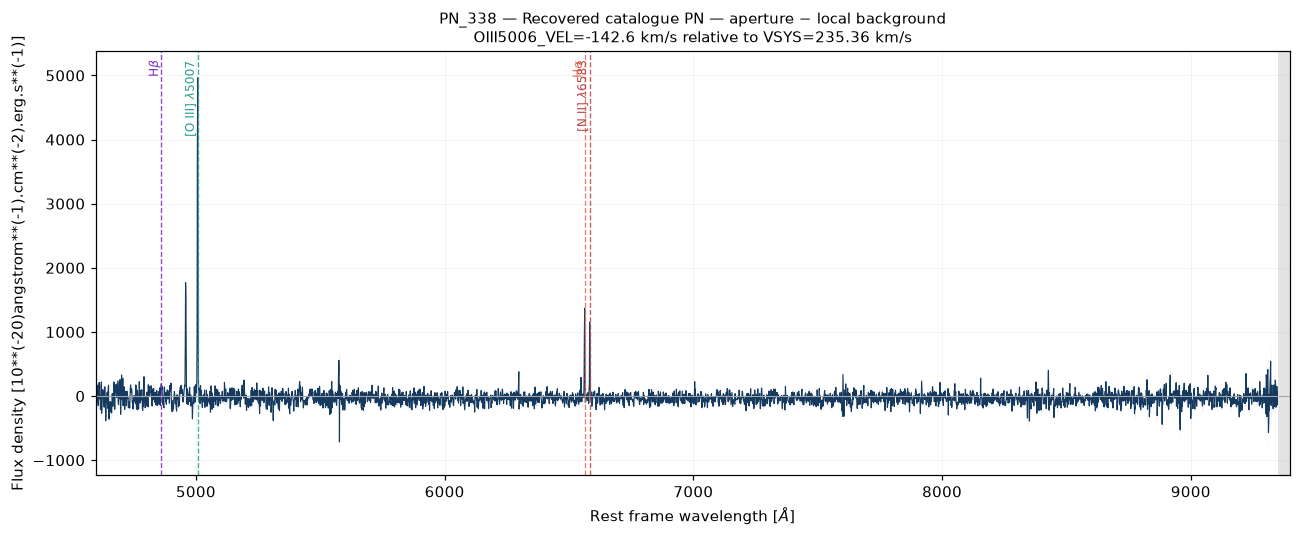

In [8]:
def load_spectrum(object_id, coordinate_mode=COORDINATE_MODE):
    run_label = f'sample{SAMPLE_PER_POPULATION}_{coordinate_mode}_seed{SAMPLE_SEED}'
    path = OUTPUT_ROOT / f'checkpoints_{run_label}' / f'{safe_object_name(object_id)}.npz'
    if not checkpoint_is_valid(path):
        raise FileNotFoundError(f'No valid checkpoint for {object_id}: {path}')
    with np.load(path, allow_pickle=False) as saved:
        return {key: saved[key].copy() for key in saved.files}

def _scalar(value):
    return value.item() if isinstance(value, np.ndarray) and value.ndim == 0 else value

def _missing_intervals(wavelength, flux, minimum_channels=2):
    missing = ~np.isfinite(flux)
    edges = np.diff(np.r_[False, missing, False].astype(int))
    starts = np.flatnonzero(edges == 1)
    stops = np.flatnonzero(edges == -1)
    intervals = []
    for start, stop in zip(starts, stops):
        if stop - start >= minimum_channels:
            intervals.append((wavelength[start], wavelength[stop - 1]))
    return intervals

def _plot_saved_spectrum(
    saved, extraction_mode='background_subtracted', normalize=None, ax=None,
    title=True, show_reference_lines=True, label_reference_lines=True,
):
    if extraction_mode == 'background_subtracted':
        flux_key, error_key = 'background_subtracted_flux', 'background_subtracted_flux_err'
        mode_label = 'aperture − local background'
    elif extraction_mode == 'aperture':
        flux_key, error_key = 'aperture_flux', 'aperture_flux_err'
        mode_label = 'aperture only'
    else:
        raise ValueError('extraction_mode must be background_subtracted or aperture')

    wave = np.asarray(saved['wavelength_rest_A'], dtype=float)
    flux = np.asarray(saved[flux_key], dtype=float).copy()
    error = np.asarray(saved[error_key], dtype=float).copy()
    scale = 1.0
    ylabel = f'Flux density [{_scalar(saved["flux_unit"])}]'
    if normalize is not None:
        if normalize != 'oiii5007_peak':
            raise ValueError('normalize must be None or oiii5007_peak')
        window = (wave >= 5000.0) & (wave <= 5014.0) & np.isfinite(flux)
        if not np.any(window) or not np.isfinite(np.nanmax(flux[window])) or np.nanmax(flux[window]) <= 0:
            raise ValueError('No positive finite [O III] 5007 peak for normalisation')
        scale = float(np.nanmax(flux[window]))
        flux /= scale
        error /= scale
        ylabel = 'Flux density / [O III] 5007 peak'

    if ax is None:
        _, ax = plt.subplots(figsize=(14, 5))
    finite = np.isfinite(wave) & np.isfinite(flux)
    # Keep NaNs in the plotted array so Matplotlib breaks the line across
    # the AO gap or any other missing interval instead of bridging it.
    ax.plot(wave, flux, color='#163a5f', linewidth=0.75)
    uncertainty = finite & np.isfinite(error)
    ax.fill_between(
        wave, flux - error, flux + error, where=uncertainty, interpolate=False,
        color='#5b8db8', alpha=0.22, linewidth=0, label=r'$1\sigma$',
    )
    for left, right in _missing_intervals(wave, flux):
        ax.axvspan(left, right, color='0.55', alpha=0.24, linewidth=0)
    if show_reference_lines:
        for line_label, (line_wave, line_color) in REFERENCE_LINES.items():
            ax.axvline(line_wave, color=line_color, linestyle='--', linewidth=0.9, alpha=0.85)
            if label_reference_lines:
                ax.text(
                    line_wave, 0.98, line_label, color=line_color, rotation=90,
                    ha='right', va='top', fontsize=8, transform=ax.get_xaxis_transform(),
                )
    ax.axhline(0, color='0.65', linewidth=0.7)
    ax.set_xlim(np.nanmin(wave), np.nanmax(wave))
    ax.set_xlabel(r'Rest frame wavelength [$\AA$]')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.18, linewidth=0.5)
    if title:
        oid = _scalar(saved['object_id'])
        population = _scalar(saved['population'])
        vrel = float(_scalar(saved['oiii5006_vel_kms']))
        vsys = float(_scalar(saved['vsys_kms']))
        ax.set_title(
            f'{oid} — {population} — {mode_label}\n'
            f'OIII5006_VEL={vrel:+.1f} km/s relative to VSYS={vsys:.2f} km/s',
            fontsize=10,
        )
    return ax

def plot_spectrum(
    object_id, extraction_mode='background_subtracted', normalize=None,
    coordinate_mode=COORDINATE_MODE, ax=None, show_reference_lines=True,
):
    saved = load_spectrum(object_id, coordinate_mode=coordinate_mode)
    return _plot_saved_spectrum(
        saved, extraction_mode=extraction_mode, normalize=normalize, ax=ax,
        show_reference_lines=show_reference_lines, label_reference_lines=show_reference_lines,
    )

# Example after the one-object test:
plot_spectrum(targets.iloc[0]['object_id'], extraction_mode='background_subtracted')
# plot_spectrum(targets.iloc[0]['object_id'], extraction_mode='aperture', normalize='oiii5007_peak')

## Paginated detected and missed grids

Only completed checkpoints are plotted. Detected and missed populations are saved to separate page sequences.

In [9]:
def build_spectra_index(target_table=targets):
    index = target_table[[
        'object_id', 'catalog_id', 'population', 'network_score', 'coordinate_source',
        'extract_ra', 'extract_dec', 'oiii5006_vel_kms', 'vsys_kms',
        'rest_correction_velocity_kms', 'checkpoint',
    ]].copy()
    index['status'] = [
        'complete' if checkpoint_is_valid(path) else 'pending' for path in index['checkpoint']
    ]
    index.to_csv(INDEX_CSV, index=False)
    return index

def save_paginated_grids(
    extraction_mode='background_subtracted', normalize=None, page_size=PAGE_SIZE,
    coordinate_mode=COORDINATE_MODE, dpi=170,
):
    if coordinate_mode != COORDINATE_MODE:
        raise ValueError('Set COORDINATE_MODE and rerun the configuration/target cells before making pages for another mode.')
    index = build_spectra_index()
    index = index[index['status'].eq('complete')]
    saved_paths = []
    ncols = 2
    nrows = math.ceil(page_size / ncols)
    for population, stem, title_color in [
        (RECOVERED, 'detected', '#176b3a'),
        (MISSED, 'missed', '#b22222'),
        (UNMATCHED, 'unmatched', '#3558a8'),
    ]:
        object_ids = index.loc[index['population'].eq(population), 'object_id'].tolist()
        n_pages = math.ceil(len(object_ids) / page_size) if object_ids else 0
        for page_number in range(n_pages):
            page_ids = object_ids[page_number * page_size:(page_number + 1) * page_size]
            fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.8 * nrows), squeeze=False, sharex=True)
            for ax, object_id in zip(axes.ravel(), page_ids):
                saved = load_spectrum(object_id, coordinate_mode=coordinate_mode)
                _plot_saved_spectrum(
                    saved, extraction_mode=extraction_mode, normalize=normalize, ax=ax,
                    title=False, show_reference_lines=True, label_reference_lines=True,
                )
                vrel = float(_scalar(saved['oiii5006_vel_kms']))
                ax.set_title(f'{object_id} , OIII5006_VEL={vrel:+.1f} km/s', fontsize=8, color=title_color)
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.tick_params(labelsize=7)
            for ax in axes.ravel()[len(page_ids):]:
                ax.axis('off')
            fig.supxlabel(r'Rest frame wavelength [$\AA$]')
            fig.supylabel('Flux density' if normalize is None else 'Flux density / [O III] 5007 peak')
            fig.suptitle(
                f'NGC 253 {population} - {extraction_mode.replace("_", " ")}\n',
                fontsize=13)
            fig.tight_layout(rect=(0.02, 0.02, 1, 0.96))
            norm_stem = 'absolute' if normalize is None else normalize
            path = PLOT_DIR / (
                f'NGC253_{stem}_{extraction_mode}_{norm_stem}_'
                f'page_{page_number + 1:03d}_of_{n_pages:03d}.png')
            fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
            plt.close(fig)
            saved_paths.append(path)
            print('Saved', path)
    return saved_paths

spectra_index = build_spectra_index()
display(spectra_index.groupby(['population', 'status']).size().rename('N').to_frame())

# After extraction finishes:
page_files = save_paginated_grids(extraction_mode='background_subtracted', normalize=None)
# Optional alternatives:
# aperture_pages = save_paginated_grids(extraction_mode='aperture', normalize=None)
# normalised_pages = save_paginated_grids(extraction_mode='background_subtracted', normalize='oiii5007_peak')

,,N
population,status,
Missed catalogue PN,complete,20
Recovered catalogue PN,complete,20
Unmatched candidate,complete,20


Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261014/NGC253_detected_background_subtracted_absolute_page_001_of_002.png
Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261014/NGC253_detected_background_subtracted_absolute_page_002_of_002.png
Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261014/NGC253_missed_background_subtracted_absolute_page_001_of_002.png
Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261014/NGC253_missed_background_subtracted_absolute_page_002_of_002.png
Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261014/NGC253_unmatched_background_subtracted_absolute_page_001_of_002.png
Saved /Users/golta/Desktop/Uni/Thesis/Codex/NGC253_cube_catalogue_spectra/pages_sample20_catalogue_seed20261

## Recommended run sequence

1. Run all cells through the function definitions.
2. Run `test_index = run_extraction(limit=1)`. ESO may occasionally return a transient 502; retries are automatic.
3. Inspect the first checkpoint with `plot_spectrum(...)` in both extraction modes.
4. Run `full_index = run_extraction()`. This processes only the fixed 30-object sample (10 per population); the completed first object is skipped. You may interrupt and resume safely.
5. Run `save_paginated_grids(...)`.

To use matched network peaks, change `COORDINATE_MODE`, rerun the configuration and target cells, and extract into the automatically separate checkpoint directory.